# Diabetes readmission: the target on the training rows

NOVA IMS Enterprise Data Science Bootcamp, 2026-27.

README, Step 4. Which encounters are readmitted in less than 30 days more often than
the others? Three outputs:

1. The `<30` rate by the variables of the project plan: `number_inpatient`,
   `discharge_disposition_desc`, `admission_source_desc`, `age`, `A1Cresult`,
   `diag_1_group`, `medical_specialty`, `n_meds_changed`, `insulin`.
2. The distributions by `race`, `gender` and `age`: the baseline of the fairness
   audit (Phase 5, D-028).
3. A short list of insights for the report and for the features.

**Training rows only.** Every number here is computed on the 59,814 training
encounters of `split_by_patient` (seed 42). Validation and test are not loaded: what
we learn by looking at the outcome must not come from the patients that will score
the models.

**Intervals by patient.** Many patients have several encounters, and these are not
independent. Each rate comes with a 95% interval that accounts for it (`rate_by` in
`src/evaluation.py`, cluster-robust standard error by patient). These are
associations, not causes: a group with a high rate is a group to look at, not a
reason.

----------------------------------------------------------------------
# STAGE 0. GET READY
----------------------------------------------------------------------

In [1]:
import sys
from pathlib import Path

PROJECT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src" / "data_prep.py").exists()
)
sys.path.insert(0, str(PROJECT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

from data_prep import add_mapping_descriptions, load_mappings, load_raw
from evaluation import rate_by
from features import GROUP, TARGET, clean, split_by_patient

SEED = 42
MIN_ROWS = 200  # smaller levels are shown together
SMALLER = "(smaller levels)"  # their label; "Other" is a real level of some columns
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Chart style: one hue for the data, quiet axes and grid, text in grey ink
SERIES = "#2a78d6"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update(
    {
        "axes.edgecolor": GRID,
        "axes.labelcolor": MUTED,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titlelocation": "left",
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "font.size": 9,
    }
)

**0.1** The training rows of the project split. The other two sets are discarded at
once.

In [2]:
df = clean(add_mapping_descriptions(load_raw(), load_mappings()))
train = split_by_patient(df, seed=SEED)[0]
del df  # validation and test are not used in this notebook
assert len(train) == 59_814

BASE_RATE = train[TARGET].mean()
print(f"{len(train):,} encounters of {train[GROUP].nunique():,} patients")
print(f"<30 rate: {BASE_RATE:.2%}")

59,814 encounters of 41,994 patients
<30 rate: 11.45%


**0.2 Two helpers.** `levels` prepares a column for the charts: an order for the
ordered variables, a cap for the counts ("6+"), and the levels with fewer than
`MIN_ROWS` encounters shown together as "(smaller levels)". `plot_rates` draws the rate of each
level with its interval; the dashed line is the overall rate.

In [3]:
def levels(col, order=None, cap=None, top=None):
    """The column `col` of `train`, ready to be compared level by level.

    Args:
        col (str): The column.
        order (list, optional): The order of the levels (otherwise by size). Every
            level of an explicit order is kept, however small.
        cap (int, optional): For counts: values from `cap` up become "cap+".
        top (int, optional): Keep only the `top` largest levels, the rest is SMALLER.

    Returns:
        pandas.Series: An ordered categorical with the same index as `train`.
    """
    values = train[col]
    if cap is not None:
        values = values.clip(upper=cap).map(lambda v: f"{v}+" if v == cap else str(v))
        order = [str(v) for v in range(cap)] + [f"{cap}+"]
    values = values.astype(str)
    counts = values.value_counts()
    keep = counts.index if order else counts[counts >= MIN_ROWS].index
    if top is not None:
        keep = keep[:top]
    values = values.where(values.isin(keep), SMALLER)
    order = [v for v in (order or list(keep)) if v in keep]
    if (values == SMALLER).any():
        order.append(SMALLER)
    return pd.Categorical(values, categories=order, ordered=True)


def table(col, **kwargs):
    """The <30 rate of each level of `col`, with its interval by patient."""
    data = pd.DataFrame(
        {col: levels(col, **kwargs), TARGET: train[TARGET], GROUP: train[GROUP]}
    )
    out = rate_by(data.sort_values(col), col, TARGET, GROUP)
    out["share"] = out["encounters"] / len(train)
    return out


def short(label, width=42):
    """A label cut to `width` characters, for the chart axes."""
    label = str(label)
    return label if len(label) <= width else label[: width - 1] + "…"


def plot_rates(t, title, ax):
    """One dot per level (its <30 rate), its 95% interval, the overall rate."""
    y = np.arange(len(t))[::-1]
    ax.hlines(y, t["low"], t["high"], color=SERIES, linewidth=2, alpha=0.45)
    ax.scatter(t["rate"], y, color=SERIES, s=36, zorder=3)
    ax.axvline(BASE_RATE, color=MUTED, linewidth=1, linestyle="--")
    ax.set_yticks(y, [f"{short(i)}  ({n:,})" for i, n in zip(t.index, t["encounters"])])
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_title(title)
    ax.set_xlabel("<30 rate (dashed: all training encounters)")

----------------------------------------------------------------------
# STAGE 1. THE <30 RATE BY THE VARIABLES OF THE PROJECT PLAN
----------------------------------------------------------------------
**1.1** One chart per variable. On the left of each level, its number of encounters.

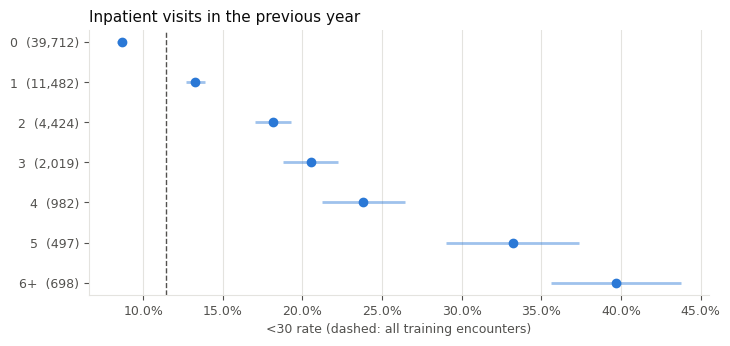

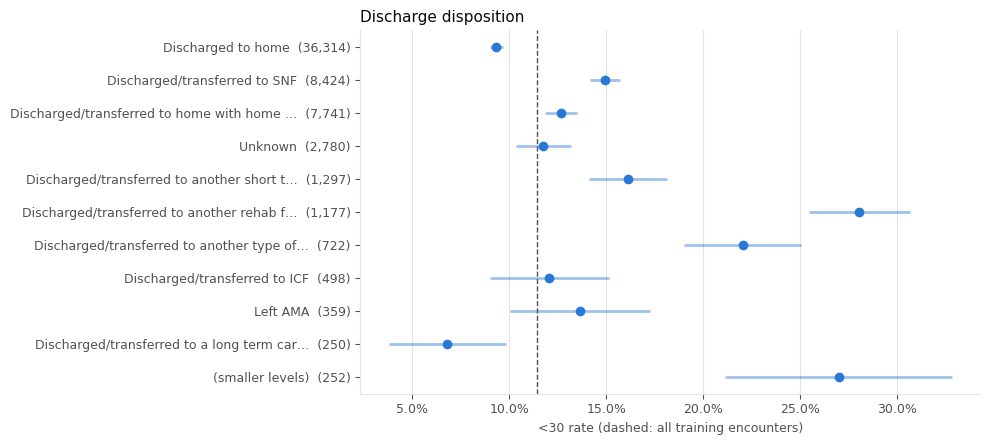

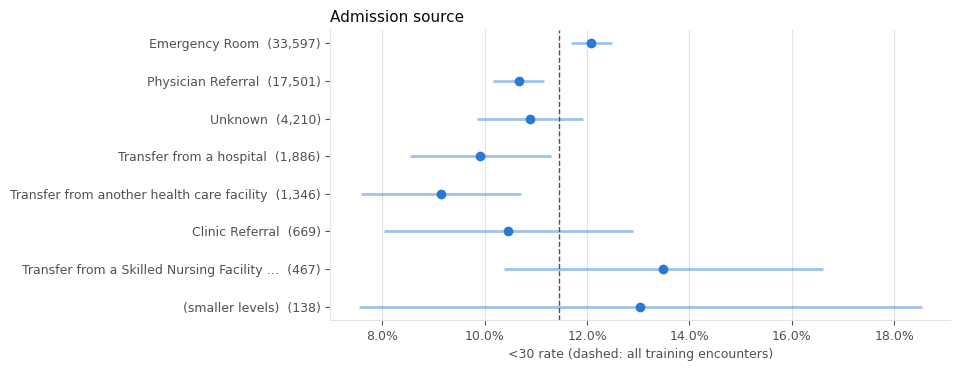

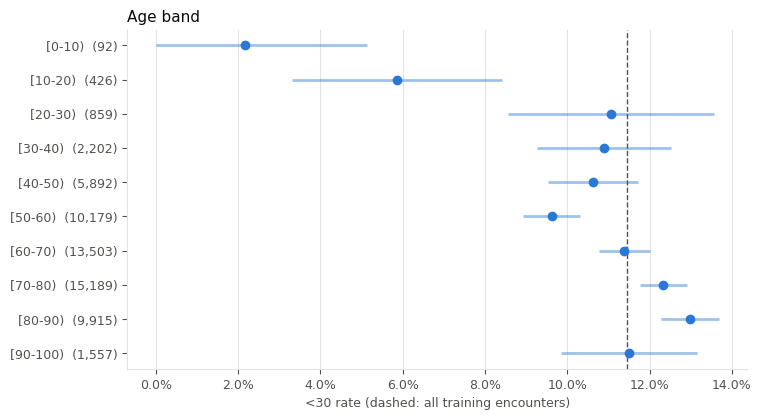

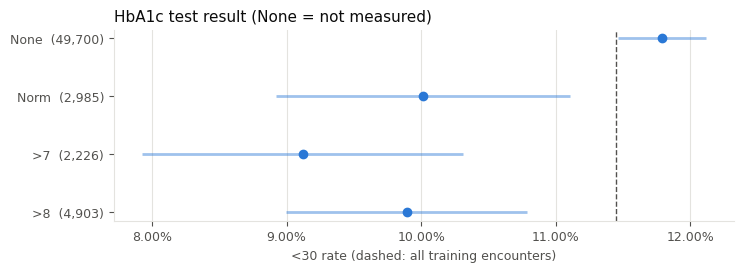

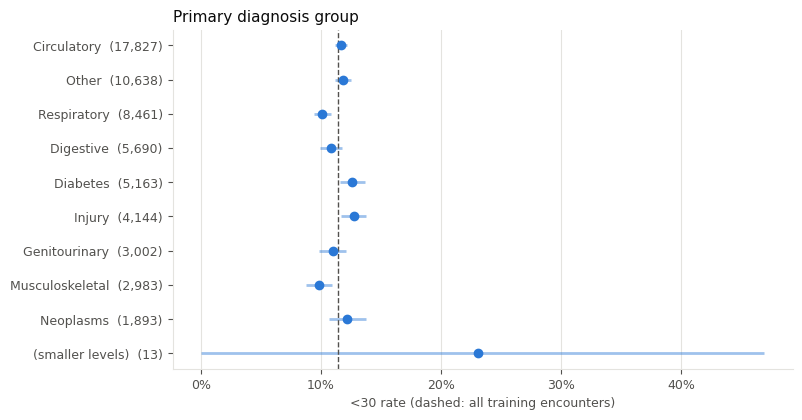

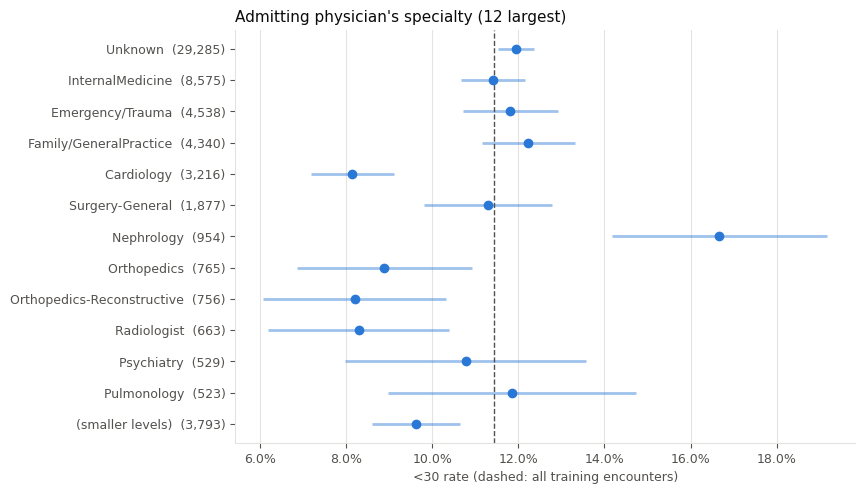

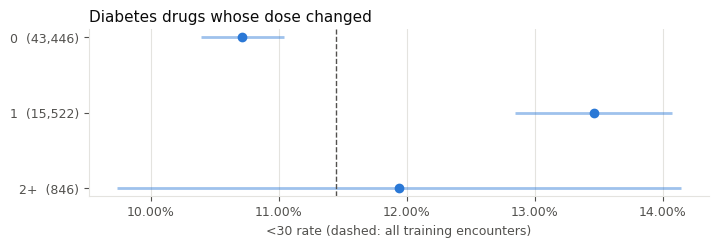

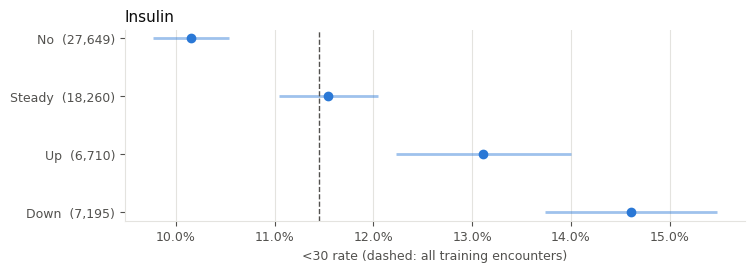

In [4]:
VARIABLES = {
    "number_inpatient": dict(cap=6),
    "discharge_disposition_desc": dict(),
    "admission_source_desc": dict(),
    "age": dict(order=sorted(train["age"].unique())),
    "A1Cresult": dict(order=["None", "Norm", ">7", ">8"]),
    "diag_1_group": dict(),
    "medical_specialty": dict(top=12),
    "n_meds_changed": dict(cap=2),
    "insulin": dict(order=["No", "Steady", "Up", "Down"]),
}
TITLES = {
    "number_inpatient": "Inpatient visits in the previous year",
    "discharge_disposition_desc": "Discharge disposition",
    "admission_source_desc": "Admission source",
    "age": "Age band",
    "A1Cresult": "HbA1c test result (None = not measured)",
    "diag_1_group": "Primary diagnosis group",
    "medical_specialty": "Admitting physician's specialty (12 largest)",
    "n_meds_changed": "Diabetes drugs whose dose changed",
    "insulin": "Insulin",
}
tables = {col: table(col, **kwargs) for col, kwargs in VARIABLES.items()}

for col, t in tables.items():
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(t) + 1.2))
    plot_rates(t, TITLES[col], ax)
    plt.show()

**1.2 The variables side by side.** For each variable: the levels with the lowest and
the highest rate, and their ratio to the overall rate. Only levels of at least
`MIN_ROWS` encounters (not the smaller levels together), so that a tiny level cannot top the list. A
wide range means the variable separates the encounters well on its own; a model can
still combine weak variables.

In [5]:
def extremes(col, t):
    """The lowest and highest rate of the real levels of one variable."""
    t = t.drop(index=SMALLER, errors="ignore")
    t = t[t["encounters"] >= MIN_ROWS]
    low, high = t["rate"].idxmin(), t["rate"].idxmax()
    return {
        "variable": col,
        "levels": len(t),
        "lowest level": short(low, 30),
        "lowest rate": t.loc[low, "rate"],
        "highest level": short(high, 30),
        "highest rate": t.loc[high, "rate"],
        "highest / overall": t.loc[high, "rate"] / BASE_RATE,
        "highest / lowest": t.loc[high, "rate"] / t.loc[low, "rate"],
    }


ranking = pd.DataFrame([extremes(col, t) for col, t in tables.items()])
ranking = ranking.set_index("variable").sort_values("highest / lowest", ascending=False)
ranking.index.name = None
ranking.style.format(
    {
        "lowest rate": "{:.1%}",
        "highest rate": "{:.1%}",
        "highest / overall": "{:.2f}x",
        "highest / lowest": "{:.2f}x",
    }
).set_caption(f"Range of the <30 rate by variable (overall {BASE_RATE:.1%})")

,levels,lowest level,lowest rate,highest level,highest rate,highest / overall,highest / lowest
number_inpatient,7,0,8.6%,6+,39.7%,3.47x,4.60x
discharge_disposition_desc,10,Discharged/transferred to a l…,6.8%,Discharged/transferred to ano…,28.0%,2.45x,4.12x
age,9,[10-20),5.9%,[80-90),13.0%,1.13x,2.21x
medical_specialty,12,Cardiology,8.1%,Nephrology,16.7%,1.46x,2.05x
admission_source_desc,7,Transfer from another health …,9.1%,Transfer from a Skilled Nursi…,13.5%,1.18x,1.48x
insulin,4,No,10.2%,Down,14.6%,1.28x,1.44x
A1Cresult,4,>7,9.1%,None,11.8%,1.03x,1.29x
diag_1_group,9,Musculoskeletal,9.9%,Injury,12.7%,1.11x,1.29x
n_meds_changed,3,0,10.7%,1,13.5%,1.18x,1.26x


**1.3** The numbers behind the charts, for the report.

In [6]:
pd.concat(
    {TITLES[col]: t for col, t in tables.items()}, names=["variable", "level"]
).style.format(
    {
        "encounters": "{:,}",
        "patients": "{:,}",
        "rate": "{:.1%}",
        "low": "{:.1%}",
        "high": "{:.1%}",
        "share": "{:.1%}",
    }
)

----------------------------------------------------------------------
# STAGE 2. RACE, GENDER AND AGE: THE BASELINE OF THE FAIRNESS AUDIT
----------------------------------------------------------------------
**2.1** How many training encounters each group has, and its `<30` rate. These are
the groups of the fairness audit (D-028). Two things matter for it:

- **Size.** A small group gives unstable metrics (wide intervals), so the audit must
  report intervals and can only compare large enough groups.
- **Base rate.** If the groups have different `<30` rates, a model cannot be
  calibrated within every group and have equal error rates in every group at the
  same time (Kleinberg et al. 2016; Chouldechova 2017): the audit must say which
  property it checks.

Following the project brief, the `Unknown/Invalid` gender encounters (2 in train)
are not reported.

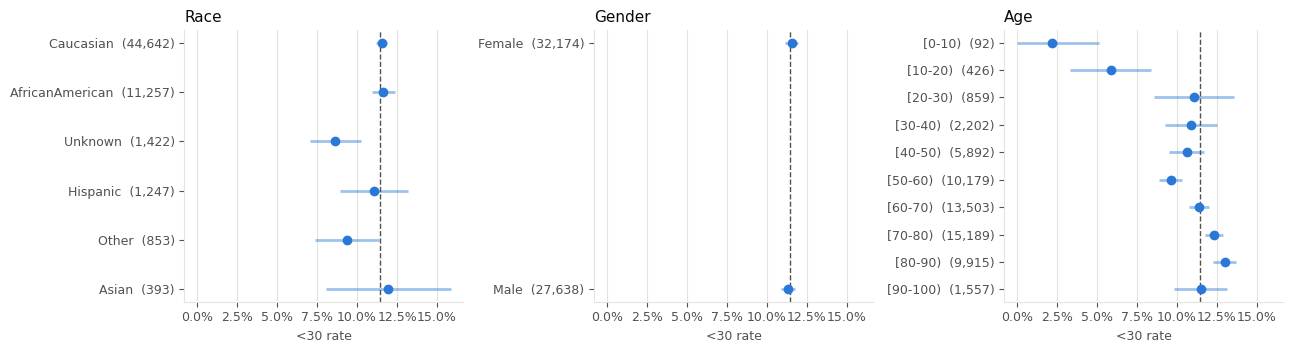

In [7]:
GROUPS = {
    "race": dict(),
    "gender": dict(),
    "age": dict(order=sorted(train["age"].unique())),
}
fairness = {}
for col, kwargs in GROUPS.items():
    t = table(col, **kwargs)
    if col == "gender":
        t = t.drop(index=["Unknown/Invalid", SMALLER], errors="ignore")
    fairness[col] = t

# One scale for the three panels, so that a small gap does not look large
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True)
for ax, (col, t) in zip(axes, fairness.items()):
    plot_rates(t, col.capitalize(), ax)
    ax.set_xlabel("<30 rate")
fig.tight_layout()
plt.show()

pd.concat(fairness, names=["group", "level"]).style.format(
    {
        "encounters": "{:,}",
        "patients": "{:,}",
        "rate": "{:.1%}",
        "low": "{:.1%}",
        "high": "{:.1%}",
        "share": "{:.1%}",
    }
).set_caption("Training encounters by group, and their <30 rate")

**2.2 Race by age.** The audit may look at intersections (D-028). This table shows
how many training encounters each combination has, with age in three bands: the
combinations below a few hundred encounters will not support a reliable comparison.

In [8]:
age_band = pd.cut(
    train["age_band_order"],
    bins=[-1, 4, 6, 9],
    labels=["under 50", "50 to 69", "70 and over"],
).astype(str)
crossed = pd.crosstab(train["race"], age_band, margins=True, margins_name="All")
crossed = crossed[["under 50", "50 to 69", "70 and over", "All"]]
crossed = crossed.loc[[*fairness["race"].index.astype(str), "All"]]
crossed.style.format("{:,}").background_gradient(
    cmap="Blues", subset=(crossed.index[:-1], crossed.columns[:-1])
).set_caption("Training encounters by race and age band")

age_band_order,under 50,50 to 69,70 and over,All
race,,,,
Caucasian,"5,810","17,052","21,780","44,642"
AfricanAmerican,"2,845","4,968","3,444","11,257"
Unknown,219,551,652,"1,422"
Hispanic,385,531,331,"1,247"
Other,162,416,275,853
Asian,50,164,179,393
All,"9,471","23,682","26,661","59,814"


----------------------------------------------------------------------
# STAGE 3. INSIGHTS
----------------------------------------------------------------------
All rates on the 59,814 training encounters (overall `<30` rate 11.45%), with 95%
intervals by patient. Associations, not causes.

**For the report**

1. **Past hospital use is the strongest signal.** The `<30` rate rises steadily with
   the inpatient visits of the previous year: 8.6% with none (two thirds of the
   encounters), 13.3% with one, 18.2% with two, 39.7% with six or more, 4.6 times the
   rate of patients with no visit. Readmission is concentrated in a minority of
   frequent users.
2. **Where the patient goes after discharge matters.** Discharged home: 9.3% (61% of
   the encounters). Transferred to a rehabilitation facility: 28.0%; to another
   inpatient care institution: 22.0%; to another short-term hospital: 16.1%; to a
   skilled nursing facility: 14.9%. A long-term care hospital is the exception (6.8%).
3. **Diabetes that is being adjusted is riskier.** Insulin dose lowered: 14.6%,
   raised: 13.1%, against 10.2% without insulin; one diabetes drug with a changed
   dose: 13.5% against 10.7% with none. A changed treatment marks a less stable
   patient.
4. **Specialty: kidney patients stand out.** Nephrology 16.7%, while Cardiology
   (8.1%), Orthopedics (8.2-8.9%) and Radiology (8.3%) are below the average. Half
   of the encounters have no recorded specialty (`Unknown`, 11.9%).
5. **Older patients are readmitted somewhat more**: 9.6% in their fifties, 13.0% in
   their eighties. The few young patients are readmitted much less (2.2% under 10,
   5.9% from 10 to 19, wide intervals).
6. **HbA1c not measured: slightly higher rate** (11.8%, 83% of the encounters)
   than measured, whatever the result (9.1-10.0%), in line with Strack et al.
   (2014). The effect is small.
7. **Weak on their own:** the primary diagnosis group (9.9-12.7%) and the admission
   source (9.1-13.5%; emergency room 12.1% against physician referral 10.7%).

**For the fairness audit (D-028)**

8. **Race and gender: similar base rates.** Caucasian 11.5%, African American
   11.6%, Hispanic 11.1%, Asian 12.0%; female 11.5%, male 11.3%. Only the encounters
   with unknown race are lower (8.6%). With similar base rates, calibration within
   groups and equal error rates are less in conflict for these groups.
9. **Age: different base rates** (from 9.6% to 13.0% among adults). This is where
   the audit must choose what to check (calibration within groups or equal recall
   at the capacity cut-off), because both cannot hold.
10. **Small groups.** Asian patients have 393 training encounters (interval
    8.1-15.9%), "Other" race 853; crossed with age, several cells have fewer than
    200 encounters (Asian under 50: 50). The audit can compare race groups as a
    whole, with intervals, but not race by age for the small groups.

**For the features and the pipeline**

11. Keep `number_inpatient` as its own feature, not only inside
    `n_visits_last_year`: it carries most of the signal, with a long tail (log1p
    for the linear models, already a pending test in README Step 5).
12. The high-risk discharge and specialty levels are small (rehabilitation: 2.0% of
    the encounters; Nephrology: 1.6%) but each has more than 100 training rows, so
    the rare-level grouping of the pipeline (D-009: top 10 levels with at least 100
    rows) keeps them. The smaller discharge levels together reach 27.0%: grouping
    them as "infrequent" mixes very different levels, a cost to remember.
13. Weak variables can still help in combination: the interaction HbA1c measured ×
    primary diagnosis of Strack et al. (D-024 d) and a comorbidity score built from
    the three diagnoses (D-024 a-b) are the natural candidates.